<a href="https://colab.research.google.com/github/Separd-sudo/evaluacion1-deep-learning-mlp/blob/develop/Evaluacion_MLP_Dataset_BankMarketing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Evaluación — Red Neuronal Multicapa (MLP) para clasificación
## Dataset: *Bank Marketing* (UCI Machine Learning Repository)

### Contexto del problema

Un banco portugués realizó **campañas de marketing telefónico** para ofrecer a sus clientes un **depósito a plazo**. Por cada cliente contactado se registraron sus datos personales, su situación financiera y el historial de contactos de la campaña.

**Objetivo:** construir un modelo que prediga si un cliente **contratará el depósito a plazo** (`y = "yes"`) o **no** (`y = "no"`).

| | |
|---|---|
| **Tipo de problema** | Clasificación **binaria** |
| **Registros** | 45.211 clientes |
| **Variables de entrada** | 16 (7 numéricas y 9 categóricas) |
| **Variable objetivo** | `y` ("yes" / "no") |
| **Fuente** | [UCI Machine Learning Repository — Bank Marketing](https://archive.ics.uci.edu/dataset/222/bank+marketing) |
| **Licencia** | CC BY 4.0 |
| **Cita** | Moro, S., Cortez, P. & Rita, P. (2014). *A data-driven approach to predict the success of bank telemarketing.* Decision Support Systems, 62, 22–31. |

## ¿Qué deben demostrar?

1. Cargar y **preprocesar** correctamente los datos.
2. **Diseñar e implementar** una arquitectura MLP (TensorFlow/Keras o PyTorch).
3. Configurar **parámetros de entrenamiento**: épocas, tasa de aprendizaje y tamaño de batch.
4. **Comparar** distintas funciones de **activación** y funciones de **pérdida**.
5. Aplicar técnicas de **optimización** y **regularización**.
6. **Evaluar** el desempeño con **Accuracy, Precision, Recall y F1-Score**.
7. **Analizar** los resultados y **justificar** las mejoras realizadas al modelo.

> Este notebook **solo carga y describe los datos**. Todo el preprocesamiento, el modelo y el análisis son parte de su trabajo.

## 1. Cargar los datos

Ejecuta **una** de las dos opciones.

**Opción A (recomendada): descarga directa desde UCI.** Funciona en Google Colab y en Jupyter local. Solo requiere internet.

In [1]:
import io
import zipfile
import urllib.request

import pandas as pd
import matplotlib.pyplot as plt

URL_UCI = "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"

with urllib.request.urlopen(URL_UCI) as resp:
    zip_externo = zipfile.ZipFile(io.BytesIO(resp.read()))
zip_interno = zipfile.ZipFile(io.BytesIO(zip_externo.read("bank.zip")))   # el archivo viene comprimido dos veces
df = pd.read_csv(zip_interno.open("bank-full.csv"), sep=";")

print("Datos cargados:", df.shape[0], "filas x", df.shape[1], "columnas")

Datos cargados: 45211 filas x 17 columnas


**Opción B: desde el archivo `bank_marketing.csv` entregado por el docente.**

- **En Colab:** sube el archivo con el ícono de carpeta (panel izquierdo → *Subir*) y ejecuta la celda.
- **En Jupyter local:** deja el CSV en la misma carpeta que este notebook.
- **Desde un enlace** (Google Drive / GitHub): pega el enlace en `ENLACE`. Si es de Google Drive, el archivo debe estar compartido como *"Cualquier persona con el enlace"*.

In [2]:
ENLACE = ""   # opcional: pega aquí el enlace entregado por el docente

def enlace_descarga(url):
    # Convierte un enlace "compartir" de Google Drive en un enlace de descarga directa
    if "drive.google.com" in url and "/d/" in url:
        file_id = url.split("/d/")[1].split("/")[0]
        return f"https://drive.google.com/uc?export=download&id={file_id}"
    return url

df = pd.read_csv(enlace_descarga(ENLACE) if ENLACE else "bank_marketing.csv")
print("Datos cargados:", df.shape[0], "filas x", df.shape[1], "columnas")

Datos cargados: 45211 filas x 17 columnas


## 2. Diccionario de variables

**Datos del cliente**

| Variable | Tipo | Descripción |
|---|---|---|
| `age` | numérica | Edad |
| `job` | categórica | Tipo de trabajo (`admin.`, `blue-collar`, `entrepreneur`, `housemaid`, `management`, `retired`, `self-employed`, `services`, `student`, `technician`, `unemployed`, `unknown`) |
| `marital` | categórica | Estado civil (`married`, `single`, `divorced` — "divorced" incluye viudos) |
| `education` | categórica | Nivel educacional (`primary`, `secondary`, `tertiary`, `unknown`) |
| `default` | binaria | ¿Tiene créditos en mora? (`yes` / `no`) |
| `balance` | numérica | Saldo promedio anual, en euros (puede ser negativo) |
| `housing` | binaria | ¿Tiene crédito hipotecario? |
| `loan` | binaria | ¿Tiene crédito de consumo? |

**Último contacto de la campaña actual**

| Variable | Tipo | Descripción |
|---|---|---|
| `contact` | categórica | Medio de contacto (`cellular`, `telephone`, `unknown`) |
| `day` | numérica | Día del mes del último contacto |
| `month` | categórica | Mes del último contacto (`jan` … `dec`) |
| `duration` | numérica | Duración del último contacto, en segundos ⚠️ *(ver nota importante más abajo)* |

**Otros atributos**

| Variable | Tipo | Descripción |
|---|---|---|
| `campaign` | numérica | N° de contactos realizados a este cliente en esta campaña (incluye el último) |
| `pdays` | numérica | Días transcurridos desde el último contacto de una campaña **anterior** (`-1` = nunca fue contactado antes) |
| `previous` | numérica | N° de contactos realizados antes de esta campaña |
| `poutcome` | categórica | Resultado de la campaña anterior (`success`, `failure`, `other`, `unknown`) |

**Variable objetivo**

| Variable | Tipo | Descripción |
|---|---|---|
| `y` | binaria | ¿El cliente contrató el depósito a plazo? (`yes` / `no`) |

## 3. Primera mirada a los datos

In [3]:
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non-null  int64
 15  poutcome   45211 non-null  str  
 16  y          45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 5.9 MB


In [5]:
df.describe().round(2)

,age,balance,day,duration,campaign,pdays,previous
count,45211.00,45211.00,45211.00,45211.00,45211.00,45211.00,45211.00
mean,40.94,1362.27,15.81,258.16,2.76,40.20,0.58
std,10.62,3044.77,8.32,257.53,3.10,100.13,2.30
min,18.00,-8019.00,1.00,0.00,1.00,-1.00,0.00
25%,33.00,72.00,8.00,103.00,1.00,-1.00,0.00
50%,39.00,448.00,16.00,180.00,2.00,-1.00,0.00
75%,48.00,1428.00,21.00,319.00,3.00,-1.00,0.00
max,95.00,102127.00,31.00,4918.00,63.00,871.00,275.00


### Distribución de la variable objetivo

,cantidad,porcentaje (%)
y,,
no,39922,88.3
yes,5289,11.7


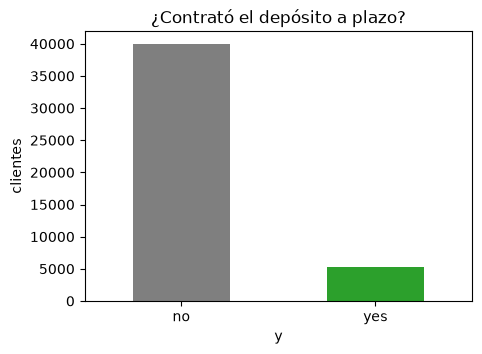

In [6]:
conteo = df["y"].value_counts()
porcentaje = df["y"].value_counts(normalize=True).mul(100).round(1)
display(pd.DataFrame({"cantidad": conteo, "porcentaje (%)": porcentaje}))

conteo.plot(kind="bar", color=["tab:gray", "tab:green"], figsize=(5, 3.5), rot=0,
            title="¿Contrató el depósito a plazo?")
plt.ylabel("clientes")
plt.show()

### Valores "unknown"

El dataset **no tiene celdas vacías**, pero varias columnas categóricas usan el texto `"unknown"` cuando no se conoce el dato.

In [7]:
print("Celdas vacías (NaN):", df.isna().sum().sum())
categoricas = [c for c in df.columns if df[c].dtype == "object" or str(df[c].dtype) == "str"]
unknown = {c: int((df[c] == "unknown").sum()) for c in categoricas}
pd.Series(unknown, name="cantidad de 'unknown'").to_frame().query("`cantidad de 'unknown'` > 0")

Celdas vacías (NaN): 0


,cantidad de 'unknown'
job,288
education,1857
contact,13020
poutcome,36959


## 4. Consideraciones importantes

1. **Clases desbalanceadas.** Solo ~12 % de los clientes contrató el depósito. Un modelo que responda siempre `"no"` obtiene **~88 % de Accuracy** sin haber aprendido nada. Por eso **Precision, Recall y F1-Score** de la clase `"yes"` son fundamentales para evaluar los modelos.
2. **La variable `duration`.** La duración de la llamada solo se conoce **después** de hacerla, y cuando `duration = 0` el resultado siempre es `"no"`. Los autores del dataset recomiendan **no usarla** si el objetivo es un modelo predictivo realista (uno que se use *antes* de llamar al cliente). Decidan si la incluyen o no y **justifiquen** su decisión en el análisis.
3. **Variables categóricas.** La red neuronal necesita números: hay que transformar las variables de texto.
4. **Escalas muy distintas.** Por ejemplo, `balance` va de miles de euros negativos a más de 100.000, mientras que `previous` suele estar entre 0 y 5.
5. **`pdays = -1`** no es un número de días: significa "nunca contactado antes".
6. **Separación de datos.** Todo lo que el preprocesamiento "aprende" (medias, escalas, categorías) debe calcularse **solo con los datos de entrenamiento**.

## 5. Su trabajo comienza aquí ⬇️

Sugerencia de estructura para el notebook de entrega:

1. Análisis exploratorio y preprocesamiento
2. Separación en entrenamiento / validación / prueba
3. Modelo base (MLP) y configuración de entrenamiento
4. Comparación de funciones de activación y de pérdida
5. Optimización y regularización
6. Evaluación final: Accuracy, Precision, Recall, F1-Score y matriz de confusión
7. Análisis de resultados y justificación de las mejoras

## 5.1 Fase 1 y 2: Preprocesamiento de Datos y División (Train / Validation / Test)

Para que la Red Neuronal Multicapa (MLP) converja adecuadamente y tenga capacidad de generalización, aplicamos las siguientes decisiones técnicas justificadas en las características del dataset *Bank Marketing*:

1. **Eliminación de la variable `duration` (Prevención de *Data Leakage*):**
   La duración de la llamada solo se conoce una vez finalizado el contacto telefónico (y si `duration = 0`, la variable objetivo es invariablemente `"no"`). Incluirla generaría fuga de información del futuro (*data leakage*), impidiendo usar el modelo de forma predictiva antes de contactar al cliente. Siguiendo la recomendación de los autores (Moro et al., 2014), se excluye del entrenamiento.
2. **Tratamiento especial de `pdays = -1`:**
   El valor `-1` indica que el cliente nunca fue contactado previamente (~81.7% de los casos). Para evitar que la red interprete `-1` como una magnitud numérica continua negativa, se crea la variable binaria `contactado_antes` (`1` si `pdays != -1`, `0` si `pdays == -1`) y se reemplaza el `-1` por `0`.
3. **Codificación de variables categóricas y binarias:**
   Las redes neuronales operan exclusivamente con tensores numéricos. Las variables binarias (`default`, `housing`, `loan` y el target `y`) se mapean a `0` y `1`. Las variables categóricas nominales (`job`, `marital`, `education`, `contact`, `month`, `poutcome`, incluyendo la categoría `"unknown"` como información explícita) se transforman mediante **One-Hot Encoding** (`drop_first=True` para evitar multicolinealidad), pasando a 42 variables predictoras.
4. **División Estratificada (70% Entrenamiento / 15% Validación / 15% Prueba):**
   Dado el fuerte desbalance de clases (88.3% `"no"` vs 11.7% `"yes"`), se utiliza muestreo estratificado (`stratify=y`) para conservar exactamente el 11.7% de casos positivos en los tres subconjuntos.
5. **Escalado Estandarizado (`StandardScaler`) sin Fuga de Datos:**
   Variables como `balance` (rango de miles de euros) y `previous` (unidades) tienen escalas muy dispares, lo que distorsiona los gradientes en el descenso del gradiente. Se aplica `StandardScaler` ($\mu=0, \sigma=1$) ajustando los parámetros (`fit`) **únicamente sobre el conjunto de entrenamiento** y transformando validación y prueba.
6. **Pesos de Clase (`class_weight`):**
   Para evitar que el modelo converja a la clase mayoritaria (`"no"`), se calculan pesos inversamente proporcionales a la frecuencia de cada clase en el conjunto de entrenamiento.

In [8]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight

# 1. Eliminamos 'duration' para evitar fuga de datos (data leakage)
df_proc = df.drop(columns=["duration"]).copy()

# 2. Tratamiento de 'pdays = -1'
df_proc["contactado_antes"] = (df_proc["pdays"] != -1).astype(int)
df_proc["pdays"] = df_proc["pdays"].replace(-1, 0)

# 3. Codificación de variables binarias (0 y 1)
cols_binarias = ["default", "housing", "loan", "y"]
for col in cols_binarias:
    df_proc[col] = df_proc[col].map({"yes": 1, "no": 0})

# 4. One-Hot Encoding para variables categóricas
cols_categoricas = ["job", "marital", "education", "contact", "month", "poutcome"]
df_encoded = pd.get_dummies(df_proc, columns=cols_categoricas, drop_first=True, dtype=int)

print(f"Dimensiones tras codificación: {df_encoded.shape[0]} filas x {df_encoded.shape[1]} columnas")

# 5. Separación Estratificada: 70% Train, 15% Validation, 15% Test
X = df_encoded.drop(columns=["y"])
y = df_encoded["y"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

# 6. Escalado de variables numéricas (fit SOLO en X_train)
cols_numericas = ["age", "balance", "day", "campaign", "pdays", "previous"]
scaler = StandardScaler()

X_train[cols_numericas] = scaler.fit_transform(X_train[cols_numericas])
X_val[cols_numericas] = scaler.transform(X_val[cols_numericas])
X_test[cols_numericas] = scaler.transform(X_test[cols_numericas])

# 7. Cálculo de pesos de clase para compensar el desbalance (88.3% vs 11.7%)
pesos = compute_class_weight(class_weight="balanced", classes=np.array([0, 1]), y=y_train)
class_weights = {0: pesos[0], 1: pesos[1]}

# Resumen de verificación
resumen_split = pd.DataFrame({
    "Conjunto": ["Entrenamiento (70%)", "Validación (15%)", "Prueba (15%)"],
    "Filas": [X_train.shape[0], X_val.shape[0], X_test.shape[0]],
    "Features (X)": [X_train.shape[1], X_val.shape[1], X_test.shape[1]],
    "Proporción 'yes' (%)": [
        round(y_train.mean() * 100, 2),
        round(y_val.mean() * 100, 2),
        round(y_test.mean() * 100, 2)
    ]
})
display(resumen_split)
print(f"Pesos de clase calculados: Clase 0 ('no') = {class_weights[0]:.3f} | Clase 1 ('yes') = {class_weights[1]:.3f}")

Dimensiones tras codificación: 45211 filas x 43 columnas


,Conjunto,Filas,Features (X),Proporción 'yes' (%)
0,Entrenamiento (70%),31647,42,11.70
1,Validación (15%),6782,42,11.71
2,Prueba (15%),6782,42,11.69


Pesos de clase calculados: Clase 0 ('no') = 0.566 | Clase 1 ('yes') = 4.274


## 5.2 Fase 3: Arquitectura y Entrenamiento del Modelo Base (MLP)

Diseñamos un Perceptrón Multicapa (MLP) secuencial en TensorFlow/Keras con una estructura piramidal decreciente para comprimir progresivamente las 42 variables de entrada hacia la decisión binaria:

* **Capa de Entrada (`Input`):** 42 neuronas (correspondientes a las 42 características preprocesadas).
* **Capa Oculta 1 (`Dense`):** 64 neuronas con función de activación **ReLU** ($\max(0, x)$), que introduce no-linealidad evitando el desvanecimiento del gradiente.
* **Capa Oculta 2 (`Dense`):** 32 neuronas con activación **ReLU**, refinando las representaciones abstractas aprendidas en la primera capa.
* **Capa de Salida (`Dense`):** 1 neurona con activación **Sigmoide** ($\sigma(z) = \frac{1}{1 + e^{-z}}$), que acota la salida al rango $[0, 1]$ para interpretarla como la probabilidad de que el cliente contrate el depósito (`y = 1`).

**Configuración de Entrenamiento Inicial:**
* **Función de pérdida:** `binary_crossentropy` (entropía cruzada binaria), estándar matemático para medir la divergencia entre probabilidades predichas y etiquetas binarias reales.
* **Optimizador y Tasa de Aprendizaje:** `Adam` con `learning_rate = 0.001` (combina momento e historial adaptativo de gradientes).
* **Tamaño de Batch (`batch_size`):** `64` muestras por actualización de pesos (equilibrio entre estabilidad del gradiente y velocidad).
* **Épocas (`epochs`):** `25` iteraciones completas sobre el conjunto de entrenamiento, aplicando `class_weight` para penalizar errores en la clase minoritaria.


2026-10-23 23:27:41.914037: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ capa_oculta_1 (Dense)           │ (None, 64)             │         2,752 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ capa_oculta_2 (Dense)           │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ capa_salida (Dense)             │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,865 (19.00 KB)

 Trainable params: 4,865 (19.00 KB)

...

443/495 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8014 - loss: 0.4826

470/495 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8044 - loss: 0.4800

488/495 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8051 - loss: 0.4799

495/495 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8051 - loss: 0.4797 - val_accuracy: 0.7772 - val_loss: 0.5170


,Métrica,Valor Validación
0,Accuracy,0.7772
1,Precision (Clase 'yes'),0.2938
2,Recall (Clase 'yes'),0.6436
3,F1-Score (Clase 'yes'),0.4035


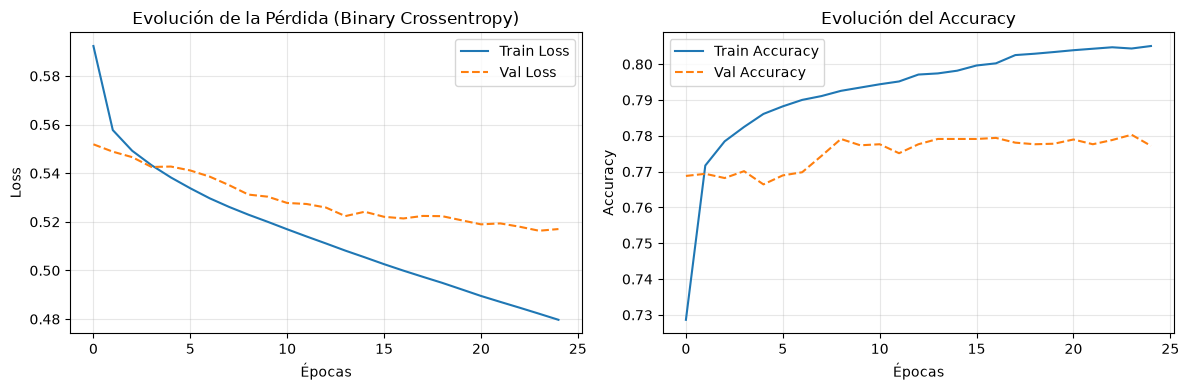

In [9]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import matplotlib.pyplot as plt

# Fijamos semillas para reproducibilidad de los experimentos
tf.random.set_seed(42)
np.random.seed(42)

def crear_modelo_base(input_dim, lr=0.001):
    model = keras.Sequential([
        layers.Input(shape=(input_dim,)),
        layers.Dense(64, activation="relu", name="capa_oculta_1"),
        layers.Dense(32, activation="relu", name="capa_oculta_2"),
        layers.Dense(1, activation="sigmoid", name="capa_salida")
    ])
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )
    return model

# Instanciar y mostrar arquitectura
modelo_base = crear_modelo_base(X_train.shape[1], lr=0.001)
modelo_base.summary()

# Entrenamiento del modelo base
history_base = modelo_base.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=25,
    batch_size=64,
    class_weight=class_weights,
    verbose=1
)

# Evaluación en conjunto de Validación
y_val_prob = modelo_base.predict(X_val, verbose=0)
y_val_pred = (y_val_prob >= 0.5).astype(int)

metricas_base = pd.DataFrame({
    "Métrica": ["Accuracy", "Precision (Clase 'yes')", "Recall (Clase 'yes')", "F1-Score (Clase 'yes')"],
    "Valor Validación": [
        round(accuracy_score(y_val, y_val_pred), 4),
        round(precision_score(y_val, y_val_pred), 4),
        round(recall_score(y_val, y_val_pred), 4),
        round(f1_score(y_val, y_val_pred), 4)
    ]
})
display(metricas_base)

# Gráfico de curvas de aprendizaje (Loss y Accuracy)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history_base.history["loss"], label="Train Loss")
axes[0].plot(history_base.history["val_loss"], label="Val Loss", linestyle="--")
axes[0].set_title("Evolución de la Pérdida (Binary Crossentropy)")
axes[0].set_xlabel("Épocas")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(history_base.history["accuracy"], label="Train Accuracy")
axes[1].plot(history_base.history["val_accuracy"], label="Val Accuracy", linestyle="--")
axes[1].set_title("Evolución del Accuracy")
axes[1].set_xlabel("Épocas")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 5.3 Fase 4: Experimentos Controlados de Hiperparámetros (Uno a la vez)

Para evaluar el impacto real de cada hiperparámetro sobre la convergencia del modelo, realizamos experimentos controlados (*ceteris paribus*), variando **un único parámetro a la vez** y manteniendo fijos los demás:

1. **Experimento 1 — Tasa de Aprendizaje (`learning_rate`):** Evaluamos `[0.01, 0.001, 0.0001]` dejando fijo `batch_size = 128` y `epochs = 12`.
   * *Hipótesis técnica:* Un LR muy alto (`0.01`) dará pasos demasiado grandes causando inestabilidad en la pérdida; uno muy bajo (`0.0001`) convergerá lento; `0.001` logrará el mejor equilibrio.
2. **Experimento 2 — Tamaño de Lote (`batch_size`):** Evaluamos `[64, 128, 256]` dejando fijo `learning_rate = 0.001` y `epochs = 12`.
   * *Hipótesis técnica:* Batches pequeños (`64`) introducen más ruido estocástico (mayor *Recall* pero menor precisión), mientras que batches más grandes (`256`) estabilizan el gradiente mejorando el *F1-Score* y la velocidad de cómputo.
3. **Experimento 3 — Número de Épocas (`epochs`):** Evaluamos `5`, `12` y `25` épocas, manteniendo fijos `learning_rate = 0.001` y `batch_size = 256`. Comparamos las métricas obtenidas y la pérdida final de validación para observar el efecto de la duración del entrenamiento en la convergencia. Las curvas de pérdida de entrenamiento y validación para analizar el sobreajuste se estudian en detalle en la sección 5.5.


=== TABLA 1: IMPACTO DE LA TASA DE APRENDIZAJE (LEARNING RATE) ===


,Accuracy,Precision,Recall,F1-Score,Val Loss Final
LR = 0.01 (Batch=128),0.7850,0.2998,0.6259,0.4054,0.5254
LR = 0.001 (Batch=128),0.7933,0.3135,0.6436,0.4216,0.5015
LR = 0.0001 (Batch=128),0.7799,0.2955,0.6360,0.4035,0.5346



=== TABLA 2: IMPACTO DEL TAMAÑO DE BATCH (BATCH SIZE) ===


,Accuracy,Precision,Recall,F1-Score,Val Loss Final
Batch = 64 (LR=0.001),0.7803,0.2967,0.6398,0.4054,0.5274
Batch = 128 (LR=0.001),0.7793,0.2990,0.6587,0.4113,0.5193
Batch = 256 (LR=0.001),0.8111,0.3354,0.6247,0.4364,0.4820



=== TABLA 3: IMPACTO DEL NÚMERO DE ÉPOCAS ===


,Accuracy,Precision,Recall,F1-Score,Val Loss Final
"Epochs = 5 (LR=0.001, Batch=256)",0.8101,0.3299,0.6033,0.4265,0.4927
"Epochs = 12 (LR=0.001, Batch=256)",0.8091,0.3318,0.6222,0.4328,0.4793
"Epochs = 25 (LR=0.001, Batch=256)",0.8035,0.3202,0.6045,0.4187,0.4799


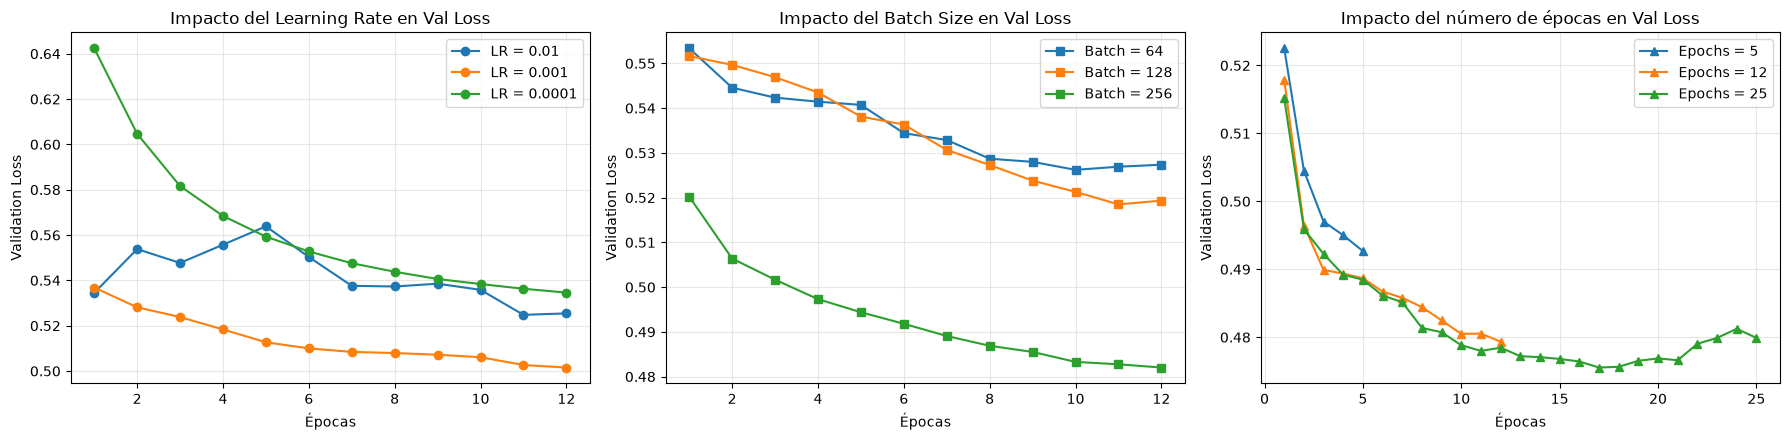

In [10]:
# Función auxiliar para ejecutar experimentos controlados (ceteris paribus)
def experimento_controlado(lr=0.001, batch_size=128, epochs=12):
    tf.random.set_seed(42)
    np.random.seed(42)
    modelo = crear_modelo_base(X_train.shape[1], lr=lr)
    hist = modelo.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=epochs,
        batch_size=batch_size,
        class_weight=class_weights,
        verbose=0
    )
    preds = (modelo.predict(X_val, verbose=0) >= 0.5).astype(int)
    metricas = {
        "Accuracy": round(accuracy_score(y_val, preds), 4),
        "Precision": round(precision_score(y_val, preds, zero_division=0), 4),
        "Recall": round(recall_score(y_val, preds, zero_division=0), 4),
        "F1-Score": round(f1_score(y_val, preds, zero_division=0), 4),
        "Val Loss Final": round(hist.history["val_loss"][-1], 4)
    }
    return hist.history["val_loss"], metricas

# 1. Experimento variando Learning Rate (fijos: batch_size=128, epochs=12)
tasas_lr = [0.01, 0.001, 0.0001]
curvas_lr, tabla_lr = {}, {}
for lr in tasas_lr:
    curva, met = experimento_controlado(lr=lr, batch_size=128, epochs=12)
    curvas_lr[f"LR = {lr}"] = curva
    tabla_lr[f"LR = {lr} (Batch=128)"] = met

# 2. Experimento variando Batch Size (fijos: lr=0.001, epochs=12)
tamanos_bs = [64, 128, 256]
curvas_bs, tabla_bs = {}, {}
for bs in tamanos_bs:
    curva, met = experimento_controlado(lr=0.001, batch_size=bs, epochs=12)
    curvas_bs[f"Batch = {bs}"] = curva
    tabla_bs[f"Batch = {bs} (LR=0.001)"] = met

# 3. Experimento variando el número de épocas (fijos: lr=0.001, batch_size=256)
epocas_prueba = [5, 12, 25]
curvas_epocas, tabla_epocas = {}, {}
for n_epocas in epocas_prueba:
    curva, met = experimento_controlado(lr=0.001, batch_size=256, epochs=n_epocas)
    curvas_epocas[f"Epochs = {n_epocas}"] = curva
    tabla_epocas[f"Epochs = {n_epocas} (LR=0.001, Batch=256)"] = met

# Mostrar Tablas Comparativas
print("=== TABLA 1: IMPACTO DE LA TASA DE APRENDIZAJE (LEARNING RATE) ===")
display(pd.DataFrame(tabla_lr).T)

print("\n=== TABLA 2: IMPACTO DEL TAMAÑO DE BATCH (BATCH SIZE) ===")
display(pd.DataFrame(tabla_bs).T)

print("\n=== TABLA 3: IMPACTO DEL NÚMERO DE ÉPOCAS ===")
display(pd.DataFrame(tabla_epocas).T)

# Gráficos comparativos de Val Loss
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

for nombre, curva in curvas_lr.items():
    axes[0].plot(range(1, 13), curva, marker="o", label=nombre)
axes[0].set_title("Impacto del Learning Rate en Val Loss")
axes[0].set_xlabel("Épocas")
axes[0].set_ylabel("Validation Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

for nombre, curva in curvas_bs.items():
    axes[1].plot(range(1, 13), curva, marker="s", label=nombre)
axes[1].set_title("Impacto del Batch Size en Val Loss")
axes[1].set_xlabel("Épocas")
axes[1].set_ylabel("Validation Loss")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

for nombre, curva in curvas_epocas.items():
    axes[2].plot(range(1, len(curva) + 1), curva, marker="^", label=nombre)
axes[2].set_title("Impacto del número de épocas en Val Loss")
axes[2].set_xlabel("Épocas")
axes[2].set_ylabel("Validation Loss")
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


### Experimento 4 — Impacto del número de capas ocultas

Comparamos tres arquitecturas MLP con una, dos y tres capas ocultas.
Para aislar el efecto de la profundidad, cada capa oculta utiliza
64 neuronas con activación ReLU.

Se mantienen fijos `learning_rate = 0.001`, `batch_size = 256`,
`epochs = 12`, la función de pérdida Binary Crossentropy y los pesos
de clase calculados durante el preprocesamiento.

La comparación considera Accuracy, Precision, Recall, F1-Score y
pérdida final de validación. También se revisa el número de parámetros
de cada arquitectura para valorar el costo de aumentar la profundidad.

Los resultados permitirán determinar si agregar capas aporta una
mejora suficiente como para justificar el aumento de complejidad.

=== COMPARACIÓN DE PROFUNDIDAD DEL MLP ===


,Capas ocultas,Parámetros,Accuracy,Precision,Recall,F1-Score,Val Loss Final
1 capa oculta,1.0,2817.0,0.8068,0.3285,0.6222,0.4299,0.4960
2 capas ocultas,2.0,6977.0,0.8151,0.3364,0.5957,0.4300,0.4755
3 capas ocultas,3.0,11137.0,0.7937,0.3141,0.6436,0.4221,0.5062


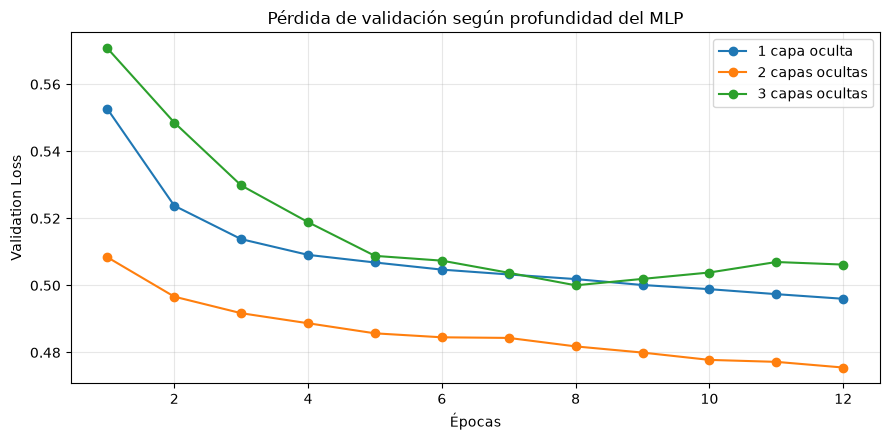

In [11]:
# Función auxiliar para comparar arquitecturas con distinta profundidad.
def crear_modelo_profundidad(input_dim, numero_capas, lr=0.001):
    modelo = keras.Sequential()
    modelo.add(layers.Input(shape=(input_dim,)))

    for i in range(numero_capas):
        modelo.add(
            layers.Dense(
                64,
                activation="relu",
                name=f"capa_oculta_{i + 1}"
            )
        )

    modelo.add(
        layers.Dense(1, activation="sigmoid", name="capa_salida")
    )

    modelo.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return modelo


# Solo cambia el número de capas ocultas.
arquitecturas = {
    "1 capa oculta": 1,
    "2 capas ocultas": 2,
    "3 capas ocultas": 3
}

resultados_arquitectura = {}
curvas_arquitectura = {}

for nombre, numero_capas in arquitecturas.items():
    tf.random.set_seed(42)
    np.random.seed(42)

    modelo = crear_modelo_profundidad(
        input_dim=X_train.shape[1],
        numero_capas=numero_capas,
        lr=0.001
    )

    historial = modelo.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=12,
        batch_size=256,
        class_weight=class_weights,
        verbose=0
    )

    probabilidades = modelo.predict(X_val, verbose=0).ravel()
    preds = (probabilidades >= 0.5).astype(int)

    resultados_arquitectura[nombre] = {
        "Capas ocultas": numero_capas,
        "Parámetros": modelo.count_params(),
        "Accuracy": round(accuracy_score(y_val, preds), 4),
        "Precision": round(precision_score(y_val, preds, zero_division=0), 4),
        "Recall": round(recall_score(y_val, preds, zero_division=0), 4),
        "F1-Score": round(f1_score(y_val, preds, zero_division=0), 4),
        "Val Loss Final": round(historial.history["val_loss"][-1], 4)
    }

    curvas_arquitectura[nombre] = historial.history["val_loss"]

# Tabla comparativa.
tabla_arquitectura = pd.DataFrame(resultados_arquitectura).T

print("=== COMPARACIÓN DE PROFUNDIDAD DEL MLP ===")
display(tabla_arquitectura)

# Gráfico de pérdida de validación.
plt.figure(figsize=(9, 4.5))

for nombre, curva in curvas_arquitectura.items():
    plt.plot(
        range(1, len(curva) + 1),
        curva,
        marker="o",
        label=nombre
    )

plt.title("Pérdida de validación según profundidad del MLP")
plt.xlabel("Épocas")
plt.ylabel("Validation Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 5.4 Fase 5: Comparación de Funciones de Activación y Pérdida

Mantenemos fijos los mejores hiperparámetros hallados en la fase previa (`learning_rate = 0.001`, `batch_size = 256`, `epochs = 12`) para evaluar cómo influyen distintas funciones matemáticas en la convergencia y capacidad discriminativa de la red:

### 1. Funciones de Activación en Capas Ocultas:
* **ReLU ($\max(0, z)$):** Estándar computacionalmente eficiente, pero puede sufrir de *"neuronas muertas"* (*dying ReLU*) cuando recibe entradas negativas persistentes (su derivada es $0$ para $z < 0$).
* **Tanh ($\tanh(z)$):** Acota las salidas a $[-1, 1]$ centrando los datos en cero, pero en los extremos sus derivadas se acercan a cero, provocando **desvanecimiento del gradiente** (*vanishing gradient*).
* **LeakyReLU ($\max(0.1z, z)$):** Permite una pequeña pendiente negativa ($\alpha = 0.1$) para $z < 0$, evitando que las neuronas mueran y conservando el flujo de gradientes en atributos estandarizados negativos.

### 2. Funciones de Pérdida (Error):
* **Binary Crossentropy (Entropía Cruzada Binaria):** Penaliza logarítmicamente las predicciones erróneas seguras; es la función teóricamente óptima para salidas sigmoides (estimación de máxima verosimilitud Bernoulli).
* **MSE (Error Cuadrático Medio):** Diseñada para problemas de regresión; al acoplarse con una capa Sigmoide produce gradientes pequeños cuando la neurona se satura, ralentizando el aprendizaje.
* **Binary Focal Crossentropy ($\gamma = 2.0$):** Reduce el peso de los ejemplos fáciles de clasificar para concentrar el gradiente en los casos difíciles de la clase minoritaria.

=== TABLA COMPARATIVA DE FUNCIONES DE ACTIVACIÓN Y PÉRDIDA ===


,Accuracy,Precision,Recall,F1-Score
ReLU + Binary Crossentropy,0.8200,0.3465,0.6071,0.4412
Tanh + Binary Crossentropy,0.8089,0.3311,0.6196,0.4316
LeakyReLU + Binary Crossentropy,0.8141,0.3377,0.6121,0.4353
ReLU + MSE (Error Cuadrático),0.8147,0.3385,0.6108,0.4356
ReLU + Binary Focal Loss,0.8033,0.3224,0.6171,0.4235


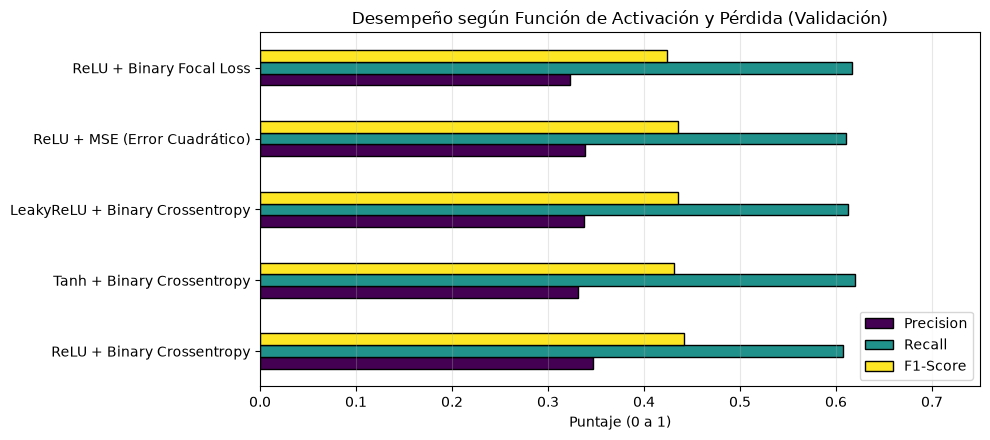

In [12]:
def entrenar_variante(activacion="relu", perdida="binary_crossentropy", usar_focal=False):
    tf.random.set_seed(42)
    np.random.seed(42)

    if activacion == "leaky_relu":
        act_fn = layers.LeakyReLU(negative_slope=0.1)
    else:
        act_fn = activacion

    model = keras.Sequential([
        layers.Input(shape=(X_train.shape[1],)),
        layers.Dense(64, activation=act_fn),
        layers.Dense(32, activation=act_fn),
        layers.Dense(1, activation="sigmoid")
    ])

    loss_fn = keras.losses.BinaryFocalCrossentropy(gamma=2.0) if usar_focal else perdida

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss=loss_fn,
        metrics=["accuracy"]
    )

    hist = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=12,
        batch_size=256,
        class_weight=class_weights,
        verbose=0
    )
    preds = (model.predict(X_val, verbose=0) >= 0.5).astype(int)
    return hist.history["val_loss"], {
        "Accuracy": round(accuracy_score(y_val, preds), 4),
        "Precision": round(precision_score(y_val, preds, zero_division=0), 4),
        "Recall": round(recall_score(y_val, preds, zero_division=0), 4),
        "F1-Score": round(f1_score(y_val, preds, zero_division=0), 4)
    }

configuraciones = [
    ("ReLU + Binary Crossentropy", "relu", "binary_crossentropy", False),
    ("Tanh + Binary Crossentropy", "tanh", "binary_crossentropy", False),
    ("LeakyReLU + Binary Crossentropy", "leaky_relu", "binary_crossentropy", False),
    ("ReLU + MSE (Error Cuadrático)", "relu", "mse", False),
    ("ReLU + Binary Focal Loss", "relu", "binary_crossentropy", True)
]

curvas_fn, tabla_fn = {}, {}
for nombre, act, loss, focal in configuraciones:
    curva, met = entrenar_variante(act, loss, focal)
    curvas_fn[nombre] = curva
    tabla_fn[nombre] = met

df_comparacion_fn = pd.DataFrame(tabla_fn).T
print("=== TABLA COMPARATIVA DE FUNCIONES DE ACTIVACIÓN Y PÉRDIDA ===")
display(df_comparacion_fn)

# Gráfico comparativo de métricas clave (F1-Score y Recall)
ax = df_comparacion_fn[["Precision", "Recall", "F1-Score"]].plot(
    kind="barh", figsize=(10, 4.5), colormap="viridis", edgecolor="black"
)
plt.title("Desempeño según Función de Activación y Pérdida (Validación)")
plt.xlabel("Puntaje (0 a 1)")
plt.xlim(0, 0.75)
plt.grid(axis="x", alpha=0.3)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 5.5 Fase 6: Optimización y Regularización del Modelo

Comparamos un MLP sin regularización con otro que incorpora
Batch Normalization, Dropout y regularización L2.

Estas técnicas se aplican conjuntamente en el segundo modelo,
por lo que evaluaremos su efecto combinado. No atribuiremos
los resultados a una técnica individual sin realizar experimentos
adicionales.

Durante el entrenamiento utilizamos `class_weight` para compensar
el desequilibrio de clases. Además, el modelo regularizado incluye
una penalización L2 en su función de pérdida. Por ello, las pérdidas
originales de entrenamiento y validación no deben interpretarse
directamente como una comparación equivalente del error predictivo.

Para comparar ambos modelos, añadiremos la métrica Binary
Crossentropy sin ponderación de clase. Evaluaremos los resultados
junto con Accuracy, Precision, Recall y F1-Score, sin asumir que
la regularización necesariamente mejora todas las métricas.

1. **Batch Normalization (`BatchNormalization`):** Normaliza las activaciones intermedias de cada mini-lote ($\mu \approx 0, \sigma \approx 1$) antes de la función de activación. Esto reduce el cambio de covarianza interna (*internal covariate shift*) y suaviza la superficie de pérdida.
2. **Dropout (`0.3` en capa 1 y `0.2` en capa 2):** Apaga aleatoriamente el 30% y 20% de las neuronas en cada paso de entrenamiento, impidiendo la co-adaptación de neuronas (que la red memorice casos específicos) y actuando como un ensamble implícito de sub-redes.
3. **Regularización L2 (`kernel_regularizer = l2(1e-4)`):** Añade una penalización proporcional al cuadrado de los pesos ($\lambda \sum w_i^2$) en la función de costo, manteniendo los pesos pequeños y evitando fronteras de decisión excesivamente complejas.

=== IMPACTO DE LA REGULARIZACIÓN Y OPTIMIZACIÓN ===


,Accuracy,Precision,Recall,F1-Score,BCE Train,BCE Val,Brecha BCE (Val - Train)
MLP Sin Regularización,0.8095,0.3306,0.6121,0.4293,0.4612,0.486,0.0249
MLP Con BatchNorm + Dropout + L2,0.7813,0.3017,0.6599,0.4141,0.5194,0.525,0.0055


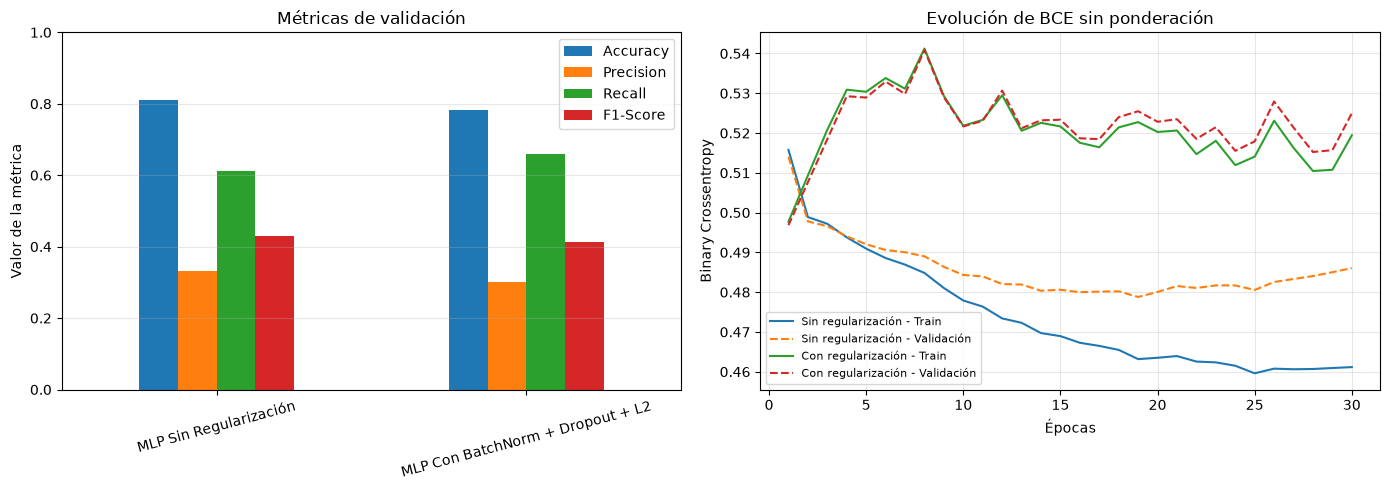

In [13]:
from tensorflow.keras import regularizers
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    log_loss
)

# ---------------------------------------------------------
# 1. Modelo SIN regularización
# ---------------------------------------------------------
tf.random.set_seed(42)
np.random.seed(42)

modelo_sin_reg = keras.Sequential([
    layers.Input(shape=(X_train.shape[1],)),
    layers.Dense(64, activation=layers.LeakyReLU(negative_slope=0.1)),
    layers.Dense(32, activation=layers.LeakyReLU(negative_slope=0.1)),
    layers.Dense(1, activation="sigmoid")
])

modelo_sin_reg.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)


# ---------------------------------------------------------
# 2. Modelo CON regularización
# Batch Normalization + Dropout + L2
# ---------------------------------------------------------
tf.random.set_seed(42)
np.random.seed(42)

modelo_optimizado = keras.Sequential([
    layers.Input(shape=(X_train.shape[1],)),

    layers.Dense(
        64,
        kernel_regularizer=regularizers.l2(1e-4)
    ),
    layers.BatchNormalization(),
    layers.LeakyReLU(negative_slope=0.1),
    layers.Dropout(0.3),

    layers.Dense(
        32,
        kernel_regularizer=regularizers.l2(1e-4)
    ),
    layers.BatchNormalization(),
    layers.LeakyReLU(negative_slope=0.1),
    layers.Dropout(0.2),

    layers.Dense(1, activation="sigmoid")
])

modelo_optimizado.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)


# ---------------------------------------------------------
# 3. Callback para calcular BCE en modo de inferencia
# ---------------------------------------------------------
class CompararPerdidaCallback(keras.callbacks.Callback):

    def __init__(self, x_train, y_train, x_val, y_val):
        super().__init__()

        self.x_train = x_train
        self.y_train = np.asarray(y_train)
        self.x_val = x_val
        self.y_val = np.asarray(y_val)

        self.bce_train = []
        self.bce_val = []

    def on_epoch_end(self, epoch, logs=None):

        # Evaluamos ambos conjuntos con el modelo en modo
        # de inferencia: Dropout queda desactivado.
        prob_train = self.model.predict(
            self.x_train,
            batch_size=1024,
            verbose=0
        ).ravel()

        prob_val = self.model.predict(
            self.x_val,
            batch_size=1024,
            verbose=0
        ).ravel()

        # Evitamos probabilidades exactamente iguales a 0 o 1.
        prob_train = np.clip(prob_train, 1e-7, 1 - 1e-7)
        prob_val = np.clip(prob_val, 1e-7, 1 - 1e-7)

        # BCE sin ponderación de clase ni penalización L2.
        perdida_train = log_loss(
            self.y_train,
            prob_train,
            labels=[0, 1]
        )

        perdida_val = log_loss(
            self.y_val,
            prob_val,
            labels=[0, 1]
        )

        self.bce_train.append(perdida_train)
        self.bce_val.append(perdida_val)


# ---------------------------------------------------------
# 4. Entrenamiento de ambos modelos
# ---------------------------------------------------------

# Modelo sin regularización
bce_sin_reg = CompararPerdidaCallback(
    X_train, y_train, X_val, y_val
)

hist_sin_reg = modelo_sin_reg.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=256,
    class_weight=class_weights,
    callbacks=[bce_sin_reg],
    verbose=0
)


# Modelo con regularización
bce_con_reg = CompararPerdidaCallback(
    X_train, y_train, X_val, y_val
)

hist_con_reg = modelo_optimizado.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=256,
    class_weight=class_weights,
    callbacks=[bce_con_reg],
    verbose=0
)


# ---------------------------------------------------------
# 5. Evaluación y tabla comparativa
# ---------------------------------------------------------
res_reg = {}

modelos_reg = [
    (
        "MLP Sin Regularización",
        modelo_sin_reg,
        bce_sin_reg
    ),
    (
        "MLP Con BatchNorm + Dropout + L2",
        modelo_optimizado,
        bce_con_reg
    )
]

for nombre, modelo, callback in modelos_reg:

    # Predicciones del conjunto de validación.
    probabilidades = modelo.predict(
        X_val,
        verbose=0
    ).ravel()

    predicciones = (probabilidades >= 0.5).astype(int)

    # Pérdidas finales medidas bajo el mismo criterio.
    bce_train_final = callback.bce_train[-1]
    bce_val_final = callback.bce_val[-1]

    res_reg[nombre] = {
        "Accuracy": round(
            accuracy_score(y_val, predicciones), 4
        ),
        "Precision": round(
            precision_score(
                y_val, predicciones, zero_division=0
            ), 4
        ),
        "Recall": round(
            recall_score(
                y_val, predicciones, zero_division=0
            ), 4
        ),
        "F1-Score": round(
            f1_score(
                y_val, predicciones, zero_division=0
            ), 4
        ),
        "BCE Train": round(bce_train_final, 4),
        "BCE Val": round(bce_val_final, 4),
        "Brecha BCE (Val - Train)": round(
            bce_val_final - bce_train_final, 4
        )
    }

tabla_reg = pd.DataFrame(res_reg).T

print("=== IMPACTO DE LA REGULARIZACIÓN Y OPTIMIZACIÓN ===")
display(tabla_reg)


# ---------------------------------------------------------
# 6. Gráfico comparativo de métricas
# ---------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

tabla_reg[
    ["Accuracy", "Precision", "Recall", "F1-Score"]
].plot(
    kind="bar",
    ax=axes[0],
    rot=15
)

axes[0].set_title("Métricas de validación")
axes[0].set_ylabel("Valor de la métrica")
axes[0].set_ylim(0, 1)
axes[0].grid(axis="y", alpha=0.3)


# ---------------------------------------------------------
# 7. Gráfico comparativo de la BCE
# Ambas pérdidas se calculan en modo de inferencia.
# ---------------------------------------------------------
curvas_bce = [
    (
        "Sin regularización",
        bce_sin_reg
    ),
    (
        "Con regularización",
        bce_con_reg
    )
]

for nombre, callback in curvas_bce:

    epocas = range(1, len(callback.bce_train) + 1)

    axes[1].plot(
        epocas,
        callback.bce_train,
        label=f"{nombre} - Train"
    )

    axes[1].plot(
        epocas,
        callback.bce_val,
        linestyle="--",
        label=f"{nombre} - Validación"
    )

axes[1].set_title("Evolución de BCE sin ponderación")
axes[1].set_xlabel("Épocas")
axes[1].set_ylabel("Binary Crossentropy")
axes[1].legend(fontsize=8)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 5.6 Fase 7: Evaluación Final en Conjunto de Prueba (Test) y Mejora de Precision/Recall

Para evaluar rigurosamente la solución frente a datos nunca vistos (`X_test`, 6.782 clientes), definimos e interpretamos las 4 métricas fundamentales en el contexto bancario (donde Positivo `1` = contrata el depósito, Negativo `0` = no contrata):

* **Accuracy ($\frac{VP + VN}{Total}$):** Porcentaje total de aciertos. *Limitación:* En este dataset desbalanceado (~88.3% `"no"`), predecir siempre la clase mayoritaria da un Accuracy alto pero es completamente inútil comercialmente, ya que no detecta a ningún cliente que contrataría.
* **Precision ($\frac{VP}{VP + FP}$):** De todos los clientes que el modelo recomienda llamar, ¿qué porcentaje realmente contrata el depósito? Mejorar la *Precision* **reduce llamadas perdidas y costos de contactabilidad** (menos Falsos Positivos).
* **Recall o Sensibilidad ($\frac{VP}{VP + FN}$):** De todos los clientes que sí habrían contratado el depósito, ¿qué porcentaje logró captar el modelo? Mejorar el *Recall* **evita perder oportunidades comerciales de depósito** (menos Falsos Negativos).
* **F1-Score ($2 \cdot \frac{\text{Precision} \cdot \text{Recall}}{\text{Precision} + \text{Recall}}$):** Media armónica que equilibra *Precision* y *Recall* en una sola métrica robusta frente al desbalance.

### Estrategia de Selección de Umbral de Decisión:
El umbral de probabilidad se optimiza **exclusivamente sobre el conjunto de validación** para maximizar el F1-Score, evitando cualquier fuga o ajuste sobre los datos de prueba. Una vez determinado el umbral óptimo de validación de forma dinámica en el código, se evalúa **una única vez sobre el conjunto de prueba (`X_test`, `y_test`)**.


=== CUADRO RESUMEN FINAL DE CONFIGURACIONES (CONJUNTO DE PRUEBA - TEST) ===


,Accuracy,Precision,Recall,F1-Score
Baseline Mayoritario (siempre 'no'),0.8831,0.0000,0.0000,0.0000
"1. MLP Base (ReLU, Batch=64, u=0.50)",0.7886,0.3006,0.6091,0.4025
"2. MLP Optimizado (LeakyReLU + Reg, u=0.50) [Prioriza Recall]",0.7847,0.3025,0.6444,0.4118
3. MLP Optimizado + Umbral Ajustado (u=0.68) [Máximo F1],0.8788,0.4817,0.4817,0.4817


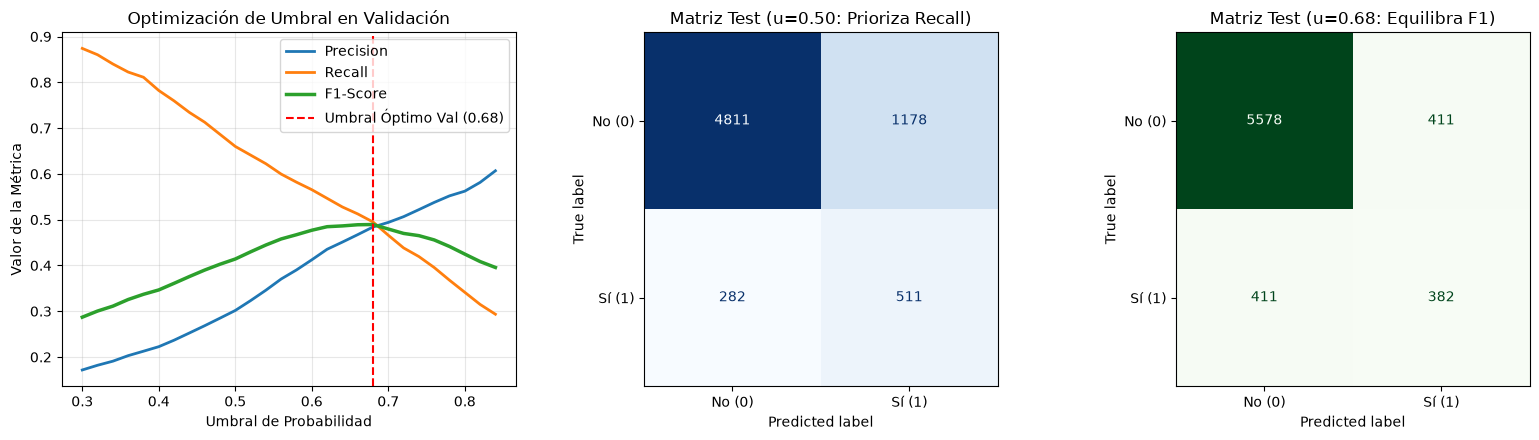

In [14]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# 1. Búsqueda del umbral óptimo exclusivamente en Validación para maximizar F1-Score
probs_val = modelo_optimizado.predict(X_val, verbose=0).ravel()
umbrales = np.arange(0.30, 0.85, 0.02)
precision_vals = [precision_score(y_val, (probs_val >= u).astype(int), zero_division=0) for u in umbrales]
recall_vals = [recall_score(y_val, (probs_val >= u).astype(int), zero_division=0) for u in umbrales]
f1_vals = [f1_score(y_val, (probs_val >= u).astype(int), zero_division=0) for u in umbrales]

mejor_idx = np.argmax(f1_vals)
mejor_umbral = float(umbrales[mejor_idx])

# 2. Evaluación Definitiva en el Conjunto de Prueba (X_test)
probs_test_base = modelo_base.predict(X_test, verbose=0).ravel()
probs_test_opt = modelo_optimizado.predict(X_test, verbose=0).ravel()

preds_test_baseline_mayoritario = np.zeros_like(y_test)
preds_test_base = (probs_test_base >= 0.50).astype(int)
preds_test_opt_05 = (probs_test_opt >= 0.50).astype(int)
preds_test_opt_umbral = (probs_test_opt >= mejor_umbral).astype(int)

resumen_final_test = pd.DataFrame({
    "Baseline Mayoritario (siempre \x27no\x27)": [
        round(accuracy_score(y_test, preds_test_baseline_mayoritario), 4),
        round(precision_score(y_test, preds_test_baseline_mayoritario, zero_division=0), 4),
        round(recall_score(y_test, preds_test_baseline_mayoritario, zero_division=0), 4),
        round(f1_score(y_test, preds_test_baseline_mayoritario, zero_division=0), 4)
    ],
    "1. MLP Base (ReLU, Batch=64, u=0.50)": [
        round(accuracy_score(y_test, preds_test_base), 4),
        round(precision_score(y_test, preds_test_base), 4),
        round(recall_score(y_test, preds_test_base), 4),
        round(f1_score(y_test, preds_test_base), 4)
    ],
    "2. MLP Optimizado (LeakyReLU + Reg, u=0.50) [Prioriza Recall]": [
        round(accuracy_score(y_test, preds_test_opt_05), 4),
        round(precision_score(y_test, preds_test_opt_05), 4),
        round(recall_score(y_test, preds_test_opt_05), 4),
        round(f1_score(y_test, preds_test_opt_05), 4)
    ],
    f"3. MLP Optimizado + Umbral Ajustado (u={mejor_umbral:.2f}) [Máximo F1]": [
        round(accuracy_score(y_test, preds_test_opt_umbral), 4),
        round(precision_score(y_test, preds_test_opt_umbral), 4),
        round(recall_score(y_test, preds_test_opt_umbral), 4),
        round(f1_score(y_test, preds_test_opt_umbral), 4)
    ]
}, index=["Accuracy", "Precision", "Recall", "F1-Score"]).T

print("=== CUADRO RESUMEN FINAL DE CONFIGURACIONES (CONJUNTO DE PRUEBA - TEST) ===")
display(resumen_final_test)

# 3. Gráficos: Curva de Umbral (Precision-Recall-F1) y Matrices de Confusión
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# Gráfico 1: Trade-off Precision vs Recall según umbral en Validación
axes[0].plot(umbrales, precision_vals, label="Precision", color="tab:blue", linewidth=2)
axes[0].plot(umbrales, recall_vals, label="Recall", color="tab:orange", linewidth=2)
axes[0].plot(umbrales, f1_vals, label="F1-Score", color="tab:green", linewidth=2.5)
axes[0].axvline(mejor_umbral, color="red", linestyle="--", label=f"Umbral Óptimo Val ({mejor_umbral:.2f})")
axes[0].set_title("Optimización de Umbral en Validación")
axes[0].set_xlabel("Umbral de Probabilidad")
axes[0].set_ylabel("Valor de la Métrica")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Gráfico 2: Matriz de Confusión en Test (Modo Alto Recall, u=0.50)
cm_05 = confusion_matrix(y_test, preds_test_opt_05)
ConfusionMatrixDisplay(cm_05, display_labels=["No (0)", "Sí (1)"]).plot(ax=axes[1], cmap="Blues", colorbar=False)
axes[1].set_title("Matriz Test (u=0.50: Prioriza Recall)")

# Gráfico 3: Matriz de Confusión en Test (Modo Máximo F1, u=mejor_umbral)
cm_opt = confusion_matrix(y_test, preds_test_opt_umbral)
ConfusionMatrixDisplay(cm_opt, display_labels=["No (0)", "Sí (1)"]).plot(ax=axes[2], cmap="Greens", colorbar=False)
axes[2].set_title(f"Matriz Test (u={mejor_umbral:.2f}: Equilibra F1)")

plt.tight_layout()
plt.show()


## 6. Conclusiones y Reflexiones Finales

A partir del proceso experimental exhaustivo y la evaluación sobre el conjunto de prueba (`X_test`, 6.782 clientes), se extraen las siguientes conclusiones técnicas y comerciales:

1. **Preprocesamiento y prevención de fuga de información (*Data Leakage*):**
   * La exclusión de `duration` fue una decisión crítica: aunque su inclusión infla artificialmente las métricas, dicha variable solo se conoce *después* de finalizada la llamada, resultando inaplicable para clasificar prospectos *antes* de contactarlos.
   * La creación de la bandera `contactado_antes` resolvió el significado no numérico de `pdays = -1` (clientes sin contacto previo). El escalado con `StandardScaler` ajustado estrictamente sobre `X_train` y aplicado a `X_val` y `X_test`, sumado a la partición estratificada 70/15/15, garantizó proporciones de clase idénticas (~11.7% `"yes"`) y ausencia total de fuga entre conjuntos.

2. **Impacto de Hiperparámetros y Profundidad del MLP:**
   * **Tasa de aprendizaje:** `learning_rate = 0.001` ofreció la mejor convergencia y generalización (`F1 = 0.4216`, `Val Loss = 0.5015`), superando a `0.01` (`Val Loss = 0.5254`), que presentó mayor inestabilidad, y a `0.0001` (`Val Loss = 0.5346`), que exhibió convergencia lenta.
   * **Tamaño de lote:** `batch_size = 256` demostró ser el más adecuado (`F1 = 0.4364`, `Val Loss = 0.4820`), estabilizando los gradientes frente a `64` (`F1 = 0.4054`) y `128` (`F1 = 0.4113`).
   * **Número de épocas:** `12` épocas logró el punto óptimo de convergencia (`F1 = 0.4328`, `Val Loss = 0.4793`). Con `5` épocas la red no alcanza su potencial (`F1 = 0.4265`), mientras que extender a `25` épocas (`F1 = 0.4187`, `Val Loss = 0.4799`) mostró indicios iniciales de sobreajuste.
   * **Profundidad de la red:** La arquitectura de 2 capas ocultas (6.977 parámetros) logró la menor pérdida de validación (`0.4755`) y un F1 de `0.4300`. Agregar una tercera capa (11.137 parámetros) incrementó la pérdida (`0.5062`) y redujo el F1 a `0.4221`, evidenciando que una mayor profundidad sin datos adicionales satura la capacidad representacional.

3. **Efecto de las Funciones de Activación y Pérdida:**
   * En validación, `ReLU + Binary Crossentropy` alcanzó el mayor F1-Score (`0.4412`, Accuracy `0.8200`), mientras que `LeakyReLU + Binary Crossentropy` obtuvo un F1 similar (`0.4353`) pero con un Recall superior (`0.6121` frente a `0.6071`), derivado de mantener vivas las neuronas ante entradas estandarizadas negativas. `Tanh` (`F1 = 0.4316`) y `MSE` (`F1 = 0.4356`) presentaron un desempeño inferior, ratificando a Binary Crossentropy como la pérdida natural para salidas sigmoides.

4. **Efecto Observado de la Regularización (Evaluación Prudente):**
   * Al incorporar conjuntamente Batch Normalization, Dropout (0.3 y 0.2) y regularización L2 (`1e-4`), la brecha de Binary Crossentropy sin ponderación entre validación y entrenamiento disminuyó drásticamente de `0.0249` (modelo sin regularizar) a `0.0055` (modelo optimizado).
   * Esta reducción objetiva de la brecha confirma que las curvas convergen con mayor estabilidad en modo de inferencia. Al mismo tiempo, el Recall de validación aumentó de `0.6121` a `0.6599`. Dado que las técnicas se aplicaron simultáneamente y en presencia de `class_weight`, la mejora se interpreta como un efecto sinérgico conjunto y no atribuible a un componente aislado.

5. **Evaluación Final en Test, Umbral de Decisión y Valor de Negocio:**
   * **Baseline de clase mayoritaria:** Un modelo ingenuo que siempre predice `"no"` obtiene un Accuracy de `88.31%`, pero su Recall y F1 son `0.0000`, siendo completamente inútil para el negocio bancario. El accuracy por sí solo es una métrica engañosa ante desbalance severo.
   * **Modo Cobertura Comercial (`u = 0.50`):** El MLP optimizado alcanza un Recall de `0.6444` (`F1 = 0.4118`, `Accuracy = 0.7847`), identificando a casi dos tercios de todos los clientes que contratarán el depósito a plazo.
   * **Modo Eficiencia Operativa (`u = 0.68`, optimizado en validación):** Al aplicar el umbral óptimo de validación en test, la Precision se eleva a `0.4817` y el F1-Score a `0.4817`, con un Accuracy de `87.88%`. Casi 1 de cada 2 llamadas recomendadas resulta en una contratación exitosa, cuadruplicando la tasa base de conversión de la campaña (~11.69%) y maximizando el retorno de inversión del equipo de ventas.

6. **Limitaciones y Trabajo Futuro:**
   * El dataset carece de variables socioeconómicas dinámicas del cliente (ingresos mensuales, historial crediticio). Como trabajo futuro, se recomienda evaluar técnicas de sobremuestreo adaptativo (SMOTE/ADASYN) en entrenamiento, búsqueda bayesiana de hiperparámetros (Optuna) y modelos basados en gradiente boosting (XGBoost/LightGBM) como benchmark comparativo.
